# e-means versus k-means on MNIST

Compare the **official e-means implementation** with Faiss Lloyd k-means and two scikit-learn references. The accompanying article uses 120 CPU fits collected November 11, 2026: two cluster counts, five seeds and twelve configurations.

This notebook contains the complete experiment, rather than calling a benchmark script. Tables and charts display inline. **Run all cells to explore the recorded measurements without downloading data or retraining.** To collect new measurements, set `RUN_FRESH = True` in the configuration cell; `SMOKE_TEST = True` then selects a small four-fit check.

Fresh runs are written outside the checkout. The article's original CSV and environment record remain unchanged. Timing results will depend on your hardware and environment.

## 1. Environment

Create a Python environment using the adjacent `requirements.txt`, select it as your notebook kernel, then restart the kernel before running all cells. From the repository root:

```sh
python3 -m venv /tmp/e-means-repro
/tmp/e-means-repro/bin/python -m pip install -r src/data/e-means/requirements.txt
```

Open `src/data/e-means/benchmark.ipynb` in VS Code or Jupyter and select that environment. In Jupyter, you can register it with `/tmp/e-means-repro/bin/python -m ipykernel install --user --name e-means --display-name "Python (e-means)"`.

The original run used Python 3.11.15 and one CPU thread. The first cell sets thread environment variables before importing numerical libraries; explicit thread limits also surround fitting and evaluation. Dependencies include Faiss's compiled CPU operations. We download the new e-means Python module separately at a fixed commit because Faiss 1.15.1 does not include it.

In [1]:
import csv
import hashlib
import importlib
import json
import os
from pathlib import Path
import platform
import sys
import time
import urllib.request
import tempfile
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from IPython.display import display, Markdown

# Set before loading any numerical libraries; also enforce with threadpoolctl.
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"

import faiss
import numpy as np
import scipy
import sklearn
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from threadpoolctl import threadpool_limits, threadpool_info


%matplotlib inline

## 2. Choose recorded results, a fresh run, or a smoke test

- `RUN_FRESH = False`: read the committed measurements and reproduce the analysis. No data or source downloads are needed.
- `RUN_FRESH = True`, `SMOKE_TEST = False`: rerun the full experiment. Allow several minutes; use a quiet machine for meaningful timings.
- `RUN_FRESH = True`, `SMOKE_TEST = True`: run all four implementations on 1,000 training and 200 test images. These results check execution, not the article's conclusions.

Start the kernel from the repository root or this notebook's directory. The output and cache paths are editable. A fresh rerun replaces previous files only in its designated rerun directory.

In [2]:
RUN_FRESH = False
SMOKE_TEST = False

CACHE_DIR = Path(tempfile.gettempdir()) / "e-means-cache"
RERUN_DIR = Path(tempfile.gettempdir()) / "e-means-notebook-rerun"
EXPORT_FIGURES = False
FIGURE_DIR = Path(tempfile.gettempdir()) / "e-means-notebook-figures"

candidates = [Path.cwd() / "src/data/e-means", Path.cwd()]
DATA_DIR = next((p for p in candidates if (p / "runs.csv").is_file()
                 and (p / "environment.json").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Start the notebook from the repository root or src/data/e-means.")
DATA_DIR = DATA_DIR.resolve()
CACHE_DIR = CACHE_DIR.resolve()
RESULTS_DIR = (RERUN_DIR / ("smoke" if SMOKE_TEST else "full")).resolve() if RUN_FRESH else DATA_DIR
if RUN_FRESH and RESULTS_DIR == DATA_DIR:
    raise ValueError("Choose a rerun directory separate from the article's original data.")
print("Mode:", "fresh smoke test" if RUN_FRESH and SMOKE_TEST else "fresh full experiment" if RUN_FRESH else "recorded article measurements")
print("Results:", RESULTS_DIR)

Mode: recorded article measurements
Results: /home/carlos/src/crojasaragonez/crojasaragonez.github.io/src/data/e-means


## 3. Pin the implementation and verify downloads

Use the unmodified official NumPy implementation from Faiss commit `f777f7d82d30a444febaa29654296738d85b3f7a`, with the defaults shipped in that commit. SHA-256 verification covers cached files as well as new downloads. The files are loaded under a separate package name so the installed Faiss package is not modified.

Sources: [official e-means code](https://github.com/facebookresearch/faiss/tree/f777f7d82d30a444febaa29654296738d85b3f7a/contrib/e_means), [paper](https://arxiv.org/abs/2611.09501), [MNIST documentation](https://keras.io/api/datasets/mnist/). Credit for MNIST: Yann LeCun, Corinna Cortes and Christopher J. C. Burges. Keras lists the dataset under CC BY-SA 3.0. The data is cached outside the repository.

In [3]:
COMMIT = "f777f7d82d30a444febaa29654296738d85b3f7a"
SOURCE = f"https://raw.githubusercontent.com/facebookresearch/faiss/{COMMIT}/contrib/e_means/"
HASHES = {
    "__init__.py": "ad196786de8eb8ab7a229908b86ad8548a72459ade95e9e9c3275943dd50bb78",
    "base.py": "bcffd7829ebfc25e1354308770b49e6f99d8566ba5e474a41a22e9ec414b17cd",
    "e_means.py": "b1710504fdbef21efdd33d8489a56f8e7fc6056182afbed3f355985302c2e77c",
}
DATA_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
DATA_HASH = "731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1"


def fetch(url, path, digest):
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(url, timeout=60) as response:
            payload = response.read()
        if hashlib.sha256(payload).hexdigest() != digest:
            raise ValueError(f"Checksum mismatch: {url}")
        path.write_bytes(payload)
    if hashlib.sha256(path.read_bytes()).hexdigest() != digest:
        raise ValueError(f"Checksum mismatch: {path}")


def prepare(cache):
    for name, digest in HASHES.items():
        fetch(SOURCE + name, cache / "official_e_means" / name, digest)
    fetch(DATA_URL, cache / "mnist.npz", DATA_HASH)
    sys.path.insert(0, str(cache))
    return importlib.import_module("official_e_means").NumpyEmeans

## 4. Load and inspect the data

Use the standard 60,000/10,000 train/test split. Flatten each 28 × 28 image into 784 contiguous float32 coordinates and divide pixels by 255. No PCA, per-feature standardization, unit normalization or learned embeddings are used. Labels never enter training.

Ten clusters asks for one group per digit class; 100 clusters permits several writing styles per class. These are different tasks. Recorded-results mode shows the original provenance instead of downloading MNIST.

In [4]:
if RUN_FRESH:
    NumpyEmeans = prepare(CACHE_DIR)
    with np.load(CACHE_DIR / "mnist.npz", allow_pickle=False) as data:
        train = np.ascontiguousarray(data["x_train"].reshape(-1, 784), dtype=np.float32) / 255
        test = np.ascontiguousarray(data["x_test"].reshape(-1, 784), dtype=np.float32) / 255
        y_train, y_test = data["y_train"], data["y_test"]
    assert train.shape == (60000, 784) and test.shape == (10000, 784)
    assert np.isfinite(train).all() and np.isfinite(test).all()
    if SMOKE_TEST:
        train, y_train = train[:1000], y_train[:1000]
        test, y_test = test[:200], y_test[:200]
    display(pd.DataFrame({"split": ["train", "test"], "rows": [len(train), len(test)],
                          "dimensions": [train.shape[1], test.shape[1]]}))
else:
    recorded_environment = json.loads((DATA_DIR / "environment.json").read_text())
    display(pd.DataFrame({"split": ["train", "test"],
                          "rows": [recorded_environment["train_shape"][0], recorded_environment["test_shape"][0]],
                          "dimensions": [recorded_environment["train_shape"][1], recorded_environment["test_shape"][1]]}))
    print("Recorded:", recorded_environment["run_utc"], "on", recorded_environment["cpu"])
    display(pd.Series(recorded_environment["versions"], name="Recorded dependency versions").to_frame())

,split,rows,dimensions
0,train,60000,784
1,test,10000,784


Recorded: 2026-11-11T18:00:15Z on AMD Ryzen AI 7 PRO 350 w/ Radeon 860M


,Recorded dependency versions
numpy,2.4.6
scipy,1.17.1
scikit-learn,1.5.2
faiss-cpu,1.15.1


## 5. Define a common evaluator

Reassign every training and test vector to its nearest **final** centroid using the same exact Faiss search for every method. MSE here means the average **squared vector distance**, summed across the 784 pixels; it is not per-pixel MSE.

ARI and arithmetic-normalized NMI measure agreement with digit labels, not classification accuracy. Occupied-cluster counts help expose collapse. Do not score e-means using its moving-pass logged objective or returned last-pass assignments.

In [5]:
def evaluate(x, labels, centers):
    # Common final-centroid evaluator. Mean squared *vector* distance, no /d.
    distances, predicted = faiss.knn(x, centers, 1)
    predicted = predicted.ravel()
    counts = np.bincount(predicted, minlength=len(centers))
    return {
        "mse": float(distances.mean(dtype=np.float64)),
        "ari": float(adjusted_rand_score(labels, predicted)),
        "nmi": float(normalized_mutual_info_score(labels, predicted)),
        "occupied": int(np.count_nonzero(counts)),
    }

## 6. Configure the four methods

The first three methods receive identical random training rows as initial centers for each `(k, seed)`. There is one initialization per fit; no best-of-many selection.

| Method | Configuration |
| --- | --- |
| Official e-means | Default automatic batch and step rules, revival and closing means; every training row, including remainder batches |
| Faiss Lloyd | Exact Euclidean assignment, one restart, default subsampling disabled |
| sklearn MiniBatchKMeans | Same batch size as five-pass e-means; early stopping disabled; five nominal epochs sampled with replacement |
| sklearn KMeans | Greedy k-means++ initialization, one restart, up to 25 Lloyd iterations; initialization timed |

MiniBatchKMeans's nominal epochs do not guarantee complete shuffled passes. The k-means++ reference selects its own centers. These are practical library comparisons, not an isolation of just one update formula.

The fit timer includes model construction, internal preparation, wrapper copies and finalization. Downloads, shared preprocessing, the shared center draw and final evaluation are excluded. The MiniBatch wrapper also resolves its batch recipe inside its timer, matching the original experiment.

In [6]:
def fit(emeans, x, init, k, seed, algorithm, epochs):
    batch = None
    alpha = None
    steps = None
    # Construction and any internal initialization are inside the timer.
    start = time.perf_counter()
    if algorithm == "e-means":
        model = emeans(x.shape[1], k, nepochs=epochs, seed=seed)
        centers, _ = model.train(x, init_centroids=init.copy())
        batch = model.recipe["batch_size"]
        alpha = model.recipe["alpha0"]
        steps = model.recipe["total_steps"]
    elif algorithm == "Lloyd (Faiss)":
        model = faiss.Kmeans(
            x.shape[1], k, niter=int(epochs), nredo=1, seed=seed,
            max_points_per_centroid=len(x),  # disable Faiss's default subsampling
        )
        model.train(x, init_centroids=init.copy())
        centers = model.centroids
        steps = len(model.iteration_stats)
    elif algorithm == "MiniBatch (sklearn)":
        # Same batch size as the 5-pass e-means recipe, no early stopping.
        recipe = emeans(x.shape[1], k, nepochs=epochs, seed=seed)
        recipe.begin(len(x), init)
        batch = recipe.recipe["batch_size"]
        model = MiniBatchKMeans(
            n_clusters=k, init=init.copy(), n_init=1, batch_size=batch,
            max_iter=int(epochs), tol=0, max_no_improvement=None,
            random_state=seed, compute_labels=False,
        ).fit(x)
        centers = model.cluster_centers_
        steps = model.n_steps_
    elif algorithm == "k-means++ (sklearn)":
        model = KMeans(
            n_clusters=k, init="k-means++", n_init=1,
            max_iter=int(epochs), tol=0, algorithm="lloyd", random_state=seed,
        ).fit(x)
        centers = model.cluster_centers_
        steps = model.n_iter_
    else:
        raise ValueError(algorithm)
    seconds = time.perf_counter() - start
    assert centers.shape == (k, x.shape[1]) and np.isfinite(centers).all()
    return np.ascontiguousarray(centers), {
        "fit_seconds": seconds, "batch_size": batch, "alpha0": alpha,
        "updates": steps,
    }

## 7. Run the experiment or load the recorded measurements

The full grid has 120 fits. e-means budgets are 1, 2.5, 5, 10 and 25 passes; Faiss Lloyd budgets are 1, 3, 5, 10 and 25 passes. The two scikit-learn reference budgets are five and 25. Use `k ∈ {10, 100}` and seeds 0–4.

Warm each implementation once, then shuffle configuration order deterministically inside each seed. Fits and evaluation run sequentially under a one-thread limit. Record hardware, versions, source and data hashes, batch sizes, update counts and train/test metrics. Changing an e-means budget changes its automatic recipe, so the curve points are **independent fits**, not checkpoints of one fit.

In [7]:
def cpu_name():
    cpuinfo = Path("/proc/cpuinfo")
    if cpuinfo.exists():
        return next((line.split(":", 1)[1].strip() for line in cpuinfo.read_text().splitlines()
                     if line.startswith("model name")), platform.processor() or "unknown")
    return platform.processor() or platform.machine()


if RUN_FRESH:
    faiss.omp_set_num_threads(1)
    seeds, ks = range(5), (10, 100)
    arms = [("e-means", t) for t in (1, 2.5, 5, 10, 25)]
    arms += [("Lloyd (Faiss)", t) for t in (1, 3, 5, 10, 25)]
    arms += [("MiniBatch (sklearn)", 5), ("k-means++ (sklearn)", 25)]
    if SMOKE_TEST:
        seeds, ks = range(1), (10,)
        arms = [(a, 2) for a in ("e-means", "Lloyd (Faiss)", "MiniBatch (sklearn)", "k-means++ (sklearn)")]
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    rows = []
    with threadpool_limits(limits=1):
        # One untimed warmup per implementation, including lazy SciPy imports.
        warm = train[:1000]
        for algorithm in ("e-means", "Lloyd (Faiss)", "MiniBatch (sklearn)", "k-means++ (sklearn)"):
            fit(NumpyEmeans, warm, warm[:10].copy(), 10, 999, algorithm, 1)
        metadata = {
            "run_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
            "python": platform.python_version(), "platform": platform.platform(),
            "cpu": cpu_name(),
            "versions": {"numpy": np.__version__, "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "faiss-cpu": faiss.__version__},
            "threadpools": threadpool_info(), "faiss_threads": faiss.omp_get_max_threads(),
            "source_commit": COMMIT, "source_sha256": HASHES, "data_url": DATA_URL,
            "data_sha256": DATA_HASH, "train_shape": list(train.shape),
            "test_shape": list(test.shape), "seeds": list(seeds), "clusters": ks,
            "arms": arms, "smoke": SMOKE_TEST,
        }
        (RESULTS_DIR / "environment.json").write_text(json.dumps(metadata, indent=2) + "\n")
        for k in ks:
            for seed in seeds:
                # Same random rows in exactly the same order for all shared-init arms.
                init_ids = np.random.RandomState(seed).permutation(len(train))[:k]
                init = train[init_ids].copy()
                run_arms = list(arms)
                np.random.default_rng(20261111 + seed + k).shuffle(run_arms)
                for algorithm, epochs in run_arms:
                    centers, stats = fit(NumpyEmeans, train, init, k, seed, algorithm, epochs)
                    row = {"k": k, "seed": seed, "algorithm": algorithm, "epochs": epochs, **stats}
                    for split, x, labels in (("train", train, y_train), ("test", test, y_test)):
                        row.update({f"{split}_{key}": val for key, val in evaluate(x, labels, centers).items()})
                    rows.append(row)
                    with (RESULTS_DIR / "runs.csv").open("w", newline="") as handle:
                        writer = csv.DictWriter(handle, fieldnames=list(row))
                        writer.writeheader()
                        writer.writerows(rows)
                    print(f"{len(rows):3d} k={k:3d} seed={seed} {algorithm:22s} T={epochs:4g} {stats['fit_seconds']:.3f}s test={row['test_mse']:.4f}", flush=True)

runs = pd.read_csv(RESULTS_DIR / "runs.csv")
environment = json.loads((RESULTS_DIR / "environment.json").read_text())
print(f"Loaded {len(runs)} fits from {RESULTS_DIR}")
display(runs.head())

Loaded 120 fits from /home/carlos/src/crojasaragonez/crojasaragonez.github.io/src/data/e-means


,k,seed,algorithm,epochs,fit_seconds,batch_size,alpha0,updates,train_mse,train_ari,train_nmi,train_occupied,test_mse,test_ari,test_nmi,test_occupied
0,10,0,e-means,10.0,0.888009,4096.0,1.0,150,39.220389,0.360320,0.482096,10,39.158375,0.367334,0.493096,10
1,10,0,e-means,1.0,0.061763,1024.0,1.0,59,39.572393,0.386382,0.495788,10,39.547547,0.385475,0.497989,10
2,10,0,e-means,25.0,2.359832,8192.0,1.0,200,39.220258,0.359586,0.481546,10,39.159731,0.366459,0.492451,10
3,10,0,e-means,5.0,0.361847,2048.0,1.0,150,39.220638,0.360346,0.481811,10,39.155987,0.366973,0.492555,10
4,10,0,Lloyd (Faiss),25.0,1.282730,NaN,NaN,25,39.439517,0.375412,0.491992,10,39.337790,0.391590,0.504711,10


## 8. Validate completeness and basic invariants

Check the actual run matrix against its environment record, reject duplicate configurations or nonfinite metrics, verify thread limits and occupancy bounds, and check the requested Lloyd iteration counts. Smoke mode expects four fits instead of 120; its results are kept separate from the full experiment.

In [8]:
expected = {(k, seed, a, float(t)) for k in environment["clusters"]
            for seed in environment["seeds"] for a, t in environment["arms"]}
actual = set(runs[["k", "seed", "algorithm", "epochs"]].itertuples(index=False, name=None))
assert len(runs) == len(actual) == len(expected) and actual == expected
assert len(runs) == (4 if environment["smoke"] else 120)
assert environment["faiss_threads"] == 1
assert all(pool["num_threads"] == 1 for pool in environment["threadpools"])
numeric = ["fit_seconds", "train_mse", "test_mse", "train_ari", "test_ari", "train_nmi", "test_nmi", "updates"]
assert np.isfinite(runs[numeric].to_numpy()).all()
assert (runs[["fit_seconds", "train_mse", "test_mse"]] > 0).all().all()
for split in ("train", "test"):
    assert ((runs[f"{split}_occupied"] > 0) & (runs[f"{split}_occupied"] <= runs["k"])).all()
lloyd = runs[runs["algorithm"] == "Lloyd (Faiss)"]
assert (lloyd["updates"] == lloyd["epochs"]).all()
print(f"Validated all {len(runs)} configurations.")

Validated all 120 configurations.


## 9. Compare quality and fit time

First show per-configuration medians and observed minima/maxima across seeds. Each table column has its own median. Then match e-means to **the same seed's** 25-pass Lloyd result: the median of these paired speedup ratios need not equal the ratio of the two median times.

Win counts use strictly lower test MSE, with no post-hoc tolerance. Five seeds describe some initialization variability; they do not provide a separate estimate of timing noise or establish statistical significance.

In [9]:
keys = ["k", "algorithm", "epochs"]
metrics = ["fit_seconds", "train_mse", "test_mse", "test_ari", "test_nmi"]
grouped = runs.groupby(keys, sort=True)
summary = grouped[metrics].agg(["median", "min", "max"])
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary = summary.reset_index()
summary["seeds"] = grouped.size().to_numpy()

main_rows = summary[(summary["algorithm"].eq("e-means") & summary["epochs"].isin([2.5, 5]))
                    | (summary["algorithm"].eq("Lloyd (Faiss)") & summary["epochs"].eq(25))
                    | summary["algorithm"].isin(["MiniBatch (sklearn)", "k-means++ (sklearn)"])]
if environment["smoke"]:
    main_rows = summary
display(main_rows[keys + [f"{m}_median" for m in metrics]].round(3))

,k,algorithm,epochs,fit_seconds_median,train_mse_median,test_mse_median,test_ari_median,test_nmi_median
4,10,Lloyd (Faiss),25.0,1.283,39.392,39.316,0.392,0.505
5,10,MiniBatch (sklearn),5.0,0.219,39.797,39.707,0.369,0.480
7,10,e-means,2.5,0.183,39.233,39.195,0.375,0.504
8,10,e-means,5.0,0.365,39.225,39.209,0.371,0.500
11,10,k-means++ (sklearn),25.0,1.186,39.413,39.406,0.366,0.485
16,100,Lloyd (Faiss),25.0,4.564,28.050,28.169,0.143,0.548
17,100,MiniBatch (sklearn),5.0,0.605,28.497,28.533,0.146,0.534
19,100,e-means,2.5,0.515,28.069,28.123,0.144,0.549
20,100,e-means,5.0,1.439,27.986,28.085,0.143,0.551
23,100,k-means++ (sklearn),25.0,7.413,28.039,28.115,0.144,0.551


In [10]:
baseline = runs[(runs["algorithm"] == "Lloyd (Faiss)") & (runs["epochs"] == 25)]
candidates = runs[(runs["algorithm"] == "e-means") & runs["epochs"].isin([2.5, 5])]
paired = candidates.merge(baseline[["k", "seed", "fit_seconds", "test_mse"]],
                           on=["k", "seed"], suffixes=("_e", "_lloyd"), validate="many_to_one")
paired["speedup"] = paired["fit_seconds_lloyd"] / paired["fit_seconds_e"]
paired["error_change_percent"] = 100 * (paired["test_mse_e"] / paired["test_mse_lloyd"] - 1)
paired["test_mse_win"] = paired["test_mse_e"] < paired["test_mse_lloyd"]
comparisons = paired.groupby(["k", "epochs"]).agg(
    seeds=("seed", "size"), test_mse_wins=("test_mse_win", "sum"),
    median_paired_speedup=("speedup", "median"), speedup_min=("speedup", "min"),
    speedup_max=("speedup", "max"), median_error_change_percent=("error_change_percent", "median"),
).reset_index()
if environment["smoke"]:
    display(Markdown("**Smoke test only:** no 25-pass baseline; full-experiment paired comparisons are omitted."))
else:
    display(comparisons.round(3))

,k,epochs,seeds,test_mse_wins,median_paired_speedup,speedup_min,speedup_max,median_error_change_percent
0,10,2.5,5,3,7.011,6.913,7.075,-0.054
1,10,5.0,5,3,3.525,3.436,3.621,-0.137
2,100,2.5,5,4,8.825,8.802,9.055,-0.140
3,100,5.0,5,5,3.195,3.146,3.229,-0.365


## 10. Explore the tradeoff visually

These figures connect medians of independent fits; shaded regions show seed minima/maxima, **not confidence intervals**. The two cluster counts have different vertical scales, which do not start at zero. Fit time uses a logarithmic axis. The scikit-learn references appear only on the time plot because their budgets have different meanings.

The recorded experiment shows e-means reaching useful squared-distance quality earlier. The ten-cluster ARI results also show that lower distance error need not mean better digit-label agreement. Neither observation establishes a universal speedup or replaces downstream evaluation.

In [11]:
COLORS = {"e-means": "#b9a2ff", "Lloyd (Faiss)": "#58d4c5", "MiniBatch (sklearn)": "#f5b866", "k-means++ (sklearn)": "#a9b5cf"}


def draw(summary, rows, mode):
    plt.rcParams.update({
        "font.family": "DejaVu Sans", "font.size": 11, "svg.fonttype": "none",
        "svg.hashsalt": "e-means-mnist-20261111", "figure.facecolor": "#101827",
        "axes.facecolor": "#101827", "axes.edgecolor": "#59657b",
        "text.color": "#edf2ff", "axes.labelcolor": "#d2dbea",
        "xtick.color": "#a9b5cf", "ytick.color": "#a9b5cf",
        "grid.color": "#344158",
    })
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 5.5), layout="constrained")
    for ax, k in zip(axes, (10, 100)):
        for algorithm in COLORS:
            group = sorted([r for r in summary if r["k"] == k and r["algorithm"] == algorithm], key=lambda r: r["epochs"])
            if mode == "epochs" and len(group) == 1:
                continue
            xs = [g["epochs"] if mode == "epochs" else g["fit_seconds_median"] for g in group]
            ys = [g["test_mse_median"] for g in group]
            ax.plot(xs, ys, "o-" if len(group) > 1 else "D", color=COLORS[algorithm], label=algorithm, markersize=5)
            if len(group) > 1:
                ax.fill_between(xs, [g["test_mse_min"] for g in group], [g["test_mse_max"] for g in group], color=COLORS[algorithm], alpha=0.10)
            for g, x, y in zip(group, xs, ys):
                if mode == "time" and algorithm in ("e-means", "Lloyd (Faiss)") and g["epochs"] in (2.5, 25):
                    ax.annotate(f"{g['epochs']:g} passes", (x, y), xytext=(-6 if g["epochs"] == 25 else 4, 12 if algorithm == "e-means" else -15), ha="right" if g["epochs"] == 25 else "left", textcoords="offset points", color=COLORS[algorithm], fontsize=9)
        ax.set_title(f"{k} clusters", loc="left", fontweight="bold")
        ax.set_ylabel("Test mean squared vector distance ↓")
        ax.set_xlabel("Training passes (log scale)" if mode == "epochs" else "Fit time, seconds (log scale)")
        ax.set_xscale("log")
        ax.grid(alpha=0.5, linewidth=0.6)
        ax.spines[["top", "right"]].set_visible(False)
        if mode == "epochs":
            ax.set_xticks([1, 2.5, 5, 10, 25], ["1", "2.5", "5", "10", "25"])
        else:
            ticks = [0.05, 0.1, 0.2, 0.5, 1, 2.5] if k == 10 else [0.2, 0.5, 1, 2, 5, 10]
            ax.set_xticks(ticks, [f"{v:g}" for v in ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False, fontsize=10)
    fig.suptitle("MNIST: quality per pass" if mode == "epochs" else "MNIST: quality versus CPU fit time", fontsize=16, fontweight="bold")
    return fig

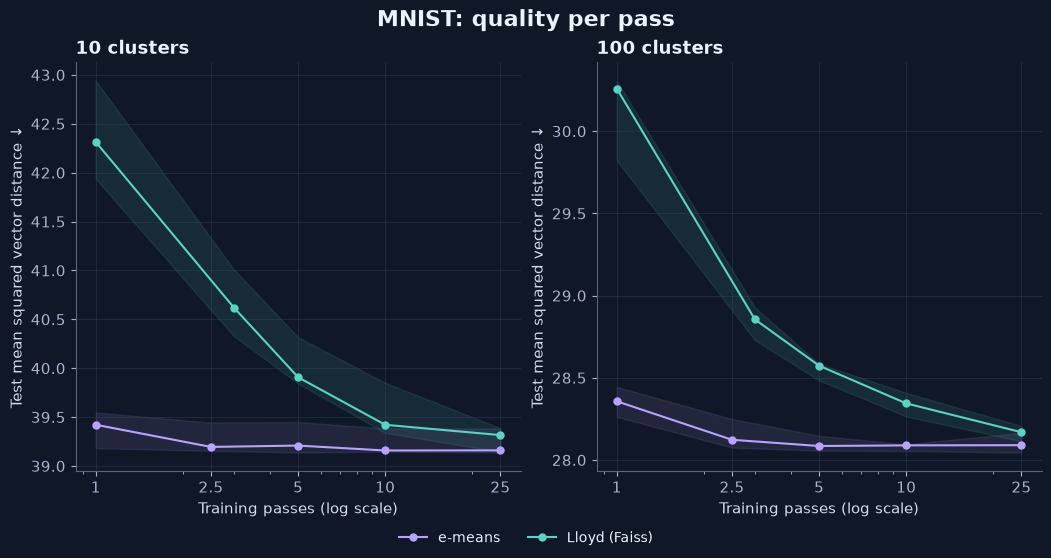

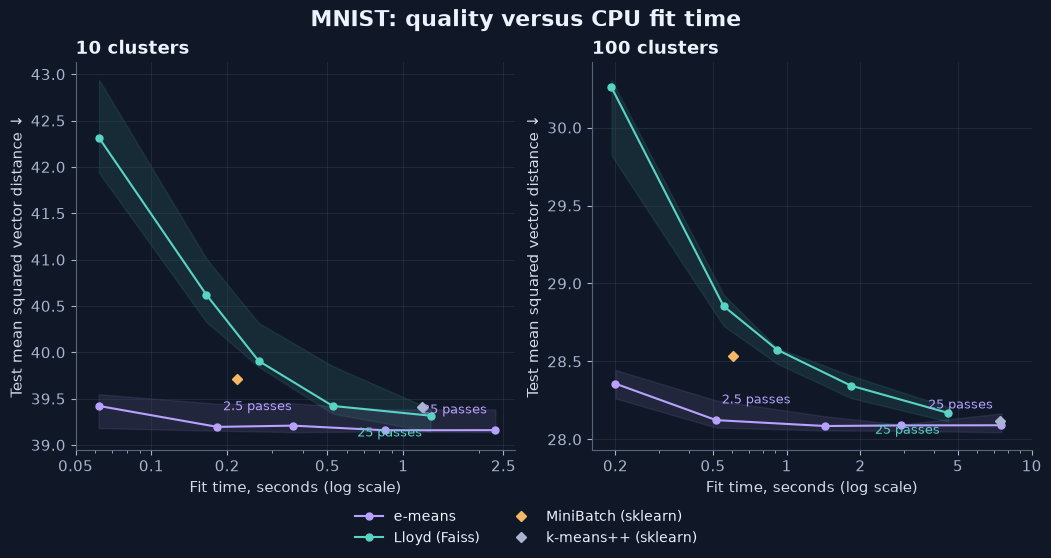

In [12]:
figures = {}
if environment["smoke"]:
    display(Markdown("Plots are reserved for the full grid; inspect the smoke-test table above."))
else:
    for mode in ("epochs", "time"):
        fig = draw(summary.to_dict("records"), runs.to_dict("records"), mode)
        figures[mode] = fig
        display(fig)
        plt.close(fig)

## 11. Save rerun summaries and optionally export figures

Fresh runs save their summaries beside the rerun CSV, outside the checkout. Set `EXPORT_FIGURES = True` near the top to export standalone SVG and PNG charts to `FIGURE_DIR`. To intentionally refresh the blog's assets, point that directory to `public/images/blog/e-means` before running this cell. Reviewing new results and updating the article's numbers remains a separate editorial step.

Recorded-results mode leaves the committed measurement files unchanged. To inspect all seed-level outcomes, use the `runs` DataFrame; `summary` and `paired` expose aggregate and matched-seed calculations.

In [13]:
if RUN_FRESH:
    summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
    comparisons.to_csv(RESULTS_DIR / "paired-comparisons.csv", index=False)
    print("Saved rerun summaries to", RESULTS_DIR)

if EXPORT_FIGURES and figures:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    description = ("MNIST CPU experiment. Five seeds. Lines connect independent-fit medians; "
                   "bands show observed seed extrema. Lower error is better.")
    for mode, fig in figures.items():
        fig.savefig(FIGURE_DIR / f"{mode}.svg", metadata={"Date": None, "Description": description})
        fig.savefig(FIGURE_DIR / f"{mode}.png", dpi=160, metadata={"Software": "Matplotlib"})
    print("Exported figures to", FIGURE_DIR)
elif not RUN_FRESH:
    print("Analysis complete; original measurements and figure assets were left unchanged.")

Analysis complete; original measurements and figure assets were left unchanged.


## Interpretation and limits

The original five-pass e-means runs beat paired 25-pass Lloyd test MSE in **3/5 seeds at 10 clusters** and **5/5 at 100 clusters**. Median paired fit-time speedups were **3.53×** and **3.19×**, respectively. These statements refer to the recorded experiment, not automatically to a fresh run.

At ten clusters, Lloyd had higher median digit-label ARI. More centroids also change the task: splitting a digit class into writing styles can improve squared-distance error while decreasing agreement with ten labels.

This is one raw-pixel dataset, one original CPU, one thread setting and five seeds, with one timing per configuration per seed. It does not replicate the paper's large embedding/GPU benchmarks or measure memory and energy. The small error differences do not establish statistical significance. For practical adoption, evaluate quality and time on your own representative workload.

See the adjacent [README](README.md) for the full protocol and provenance; the article is [Faster Clustering: What e-means Could Save Companies](../../content/blog/e-means-vs-k-means-on-mnist.md).